# Business AI analytics: Should we roll out the AI-written campaign?

**Self-study tutorial · November 2026 · 60–75 minutes**

You lead analytics for Alder Market, a fictional retailer. Marketing wants to replace its standard discount email with an AI-written version. Your recommendation has to survive three checks: Is the copy comparable to past offers? Did the new version cause more purchases? Is the evidence strong enough to justify rollout?

Work through the case in order. Predict the result at each **Try it** prompt before running the next cell. At the end, write a five-line decision memo and test an AI analyst on the same evidence. You can read the saved outputs first, then rerun or modify them in Jupyter.

**Setup.** Use a Python 3.10+ Jupyter kernel with scikit-learn and Matplotlib. From the repository root, install the dependencies with `python -m pip install -r requirements.txt`. Open the notebook in JupyterLab and choose **Restart Kernel and Run All Cells**. All campaign records and sample responses are synthetic. The main path runs offline without credentials, model calls, or external data. The final model exercise is optional.

## 1 · Read the evidence behind the workflow

| 2026 reading | What to carry into the case | What the evidence covers |
|---|---|---|
| **Ellickson et al., [Evaluating Novel Unstructured Treatments with Generative AI](https://doi.org/10.1177/00222437261476639).** Read the empirical context and the sections on incumbent–challenger decisions and local support. | Represent text, check whether a proposed creative lies near historical examples, and decide whether the prediction is credible enough to use. | The paper used observational targeted-promotion logs with **34 subject-line treatments**, estimated historical effects using doubly robust methods, and evaluated held-out creatives retrospectively. Its new AI-generated candidates had *predicted* lift. The notebook uses a small synthetic archive and a lexical screen. |
| **Fang et al., [Generative Artificial Intelligence and Sales Productivity](https://doi.org/10.1287/mnsc.2026.00623).** Read the abstract and compare the presale-service arms in the [author working paper, Appendix C](https://thearf-org-unified-admin.s3.amazonaws.com/MSI/2026/MSI_Report_26-112.pdf#page=47). | Test against the actual incumbent and measure business outcomes alongside customer guardrails. | The published study tests seven randomized workflows at one cross-border retailer. Short-run sales effects ranged from no detectable change to 16.3%, with gains mainly through conversion. In the working paper, the 16.3% chatbot result compares with unavailable presale support. The estimate against human-only support was smaller and inconclusive. |
| **Dell’Acqua et al., [Navigating the Jagged Technological Frontier](https://doi.org/10.1287/orsc.2025.21838).** Read [Figure 5 in the open full text](https://www.hbs.edu/ris/Publication%20Files/dell-acqua-et-al-2026-navigating-the-jagged-technological-frontier_5c589c8c-fbb5-458f-b285-c944746cd717.pdf#page=12). | Verify each decision-critical claim, especially when the AI's prose is persuasive. | In the consulting experiment, results varied by task. On one difficult task, 84.5% of controls were correct versus 60.0% and 70.6% in the two GPT-4 arms, a pooled drop of roughly **19 percentage points**. |
| **Tomitsuka et al., [Argo-Bench](https://arxiv.org/html/2610.02122#S3), and Patel et al., [BusinessCaseBench](https://arxiv.org/html/2607.16057v5#S3).** Both are preprints. | Test the complete decision, including the source, metric, calculation, and action. Track how often every required check passes. | Argo-Bench scores outcomes in a simulated firm. The best tested model earned at least 95/100 on 34.8% of tasks. BusinessCaseBench scores answers to open-ended business cases against instructor rubrics. For its leading tested model, 88.4% average rubric credit coexisted with 49.6% of answers meeting every criterion. |

Two course readings connect these methods to the classroom. [Jurafsky and Martin, Ch. 5](https://web.stanford.edu/~jurafsky/slp3/5.pdf) explains embeddings, and [Ch. 11](https://web.stanford.edu/~jurafsky/slp3/11.pdf) explains retrieval and grounding. The book is listed in [Eccles Marketing Text Analytics](https://class-tools.app.utah.edu/syllabus/1264/12473/MKTG%2B4640%2BSyllabus.pdf). Scott Murff's [Models in Your Product](https://byu-strategy.github.io/product-management/11-models-in-your-product.html#evals-knowing-whether-it-works) shows how BYU Marriott students design task-specific evaluations.

**Reading check.** Which source can establish that AI caused an outcome in a live business? Which tests model capabilities in a simulated firm? Which estimates effects from observational records? Your answer should identify the comparison and the data behind each claim.

## 2 · Screen the AI-written subject line

Alder's incumbent advertises **10% off eligible home goods to subscribed customers**. Compare three proposed subjects with an archive in which the audience, discount, and channel are recorded explicitly. The same wording directed at a different audience can carry a different business and consent context.

Use TF–IDF and cosine similarity as a transparent text baseline. Fit the vocabulary and weights on the archive only. A close match gives an analyst relevant precedents to inspect. The routing policy sends unfamiliar copy to experiment design and a scope mismatch to human review. The score has no unit of sales lift.

**Try it.** Which two candidates should have identical similarity scores? Which one has a scope mismatch? Decide before running the cell.

In [1]:
from dataclasses import asdict, dataclass, replace
import json
from math import isclose, isfinite, sqrt

%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


@dataclass(frozen=True)
class Creative:
    id: str
    subject: str
    audience: str = "subscribed-customers"
    offer: str = "10%-off-home-goods"
    channel: str = "email"


archive = [
    Creative("H01", "Save 10% on home essentials this weekend"),
    Creative("H02", "Weekend offer: take 10% off your home favorites"),
    Creative("H03", "Refresh your home and save 10% on everyday essentials"),
    Creative("H04", "Kitchen staples: take 10% off this weekend"),
    Creative("H05", "Bedding favorites: save 10% on your next order"),
    Creative("H06", "Save 10% on storage and home organization"),
]

campaign_subject = "Save 10% on home essentials this weekend only"
candidates = [
    Creative("A", campaign_subject),
    Creative("B", "Unlock a surprise curated edit"),
    Creative("C", campaign_subject, audience="prospects"),
]

# Illustrative and fixed before looking at the candidate scores.
SIMILARITY_FLOOR = 0.40


def screen(history, candidate, similarity_floor=SIMILARITY_FLOOR):
    encoder = TfidfVectorizer(ngram_range=(1, 2))
    historical_vectors = encoder.fit_transform([item.subject for item in history])
    candidate_vector = encoder.transform([candidate.subject])
    similarities = cosine_similarity(candidate_vector, historical_vectors)[0]
    nearest = max(range(len(history)), key=lambda index: similarities[index])
    match = history[nearest]
    similarity = float(similarities[nearest])

    def scope(creative):
        return creative.audience, creative.offer, creative.channel

    scoped_indices = [
        index for index, item in enumerate(history) if scope(item) == scope(candidate)
    ]
    if not scoped_indices:
        return "human_review", match.id, similarity

    nearest_in_scope = max(scoped_indices, key=lambda index: similarities[index])
    match = history[nearest_in_scope]
    similarity = float(similarities[nearest_in_scope])
    route = "inspect_precedent" if similarity >= similarity_floor else "design_experiment"
    return route, match.id if similarity > 0 else None, similarity


for candidate in candidates:
    route, neighbor, score = screen(archive, candidate)
    print(f"{candidate.id}: {score:.2f}  closest={neighbor or 'none'}  {route}")

assert [screen(archive, item)[0] for item in candidates] == [
    "inspect_precedent", "design_experiment", "human_review"
]

A: 1.00  closest=H01  inspect_precedent
B: 0.00  closest=none  design_experiment
C: 1.00  closest=H01  human_review


**Check your answer.** A and C have the same text, so their lexical similarity to H01 is identical. Both score 1.00 because the only added token, “only,” is outside the learned vocabulary. C has no eligible comparison in the archive. B has little word overlap and may be unfamiliar, although a human reader or an embedding model could detect meaning that word overlap misses.

**Try it · Transfer to embeddings.** Add a true paraphrase of H01 with fewer shared words. Can this baseline rank it above a similar-sounding subject that changes the offer? A modern embedding model can capture semantic similarity. Keep the scope check either way. Before using a production cutoff, hold out complete creatives or campaigns; estimate how similarity relates to errors against independently measured lift. Splitting customers from the same creative across train and test would leak the text identity. Six subjects here are enough to demonstrate routing. They are too few to validate a lift model or a threshold.

## 3 · Estimate the effect of changing the copy

Alder randomly assigns 40,000 eligible recipients to its current email or candidate A, with 20,000 in each arm. The two versions have the same body, offer, eligibility, timing, and checkout experience. This fictitious packet represents the end of a fixed seven-day test.

- **Primary outcome.** Did the assigned recipient make at least one purchase within seven days?
- **Estimand.** The difference in seven-day purchase probability under assignment to A versus assignment to the incumbent, among eligible recipients.
- **Guardrail.** An increase of **0.30 percentage points** in unsubscribe probability is the maximum allowed.
- **Economics.** The business budgets **\$24 contribution per incremental purchasing recipient** after relevant variable costs and the discount. The variant adds **\$0.08 per assigned recipient** at the contemplated rollout scale. Contribution is held fixed for this exercise.
- **Decision rule set before reading results.** Recommend expansion for human approval when the lower limit of the purchase-lift interval clears break-even and the upper limit of the unsubscribe interval stays within the guardrail. Hold immediately if the observed guardrail reaches its limit. Retain the incumbent when even the upper limit of purchase lift fails to clear break-even. Collect more evidence when the intervals leave the decision open. Block pending review if required evidence is missing or the window has yet to close.

**Try it.** Calculate the raw purchase rates, absolute lift, and relative lift by hand. Which count belongs in the denominator? Is purchase rate among recipients who opened the email the same estimand?

In [2]:
@dataclass(frozen=True)
class Arm:
    assigned: int
    purchases: int
    unsubscribes: int
    opens: int


@dataclass(frozen=True)
class Trial:
    evidence_id: str
    control: Arm
    variant: Arm
    mature_window: bool = True
    margin: float = 24.00
    extra_cost: float | None = 0.08


base = Trial(
    evidence_id="ALDER-AB-01",
    control=Arm(20_000, 1_000, 150, 4_200),
    variant=Arm(20_000, 1_150, 166, 6_000),
)
GUARDRAIL = 0.003

print("Arm            Assigned    Buyers    Unsubs     Opens")
for name, arm in (("Incumbent", base.control), ("AI subject", base.variant)):
    print(f"{name:<12}{arm.assigned:>11,}{arm.purchases:>10,}"
          f"{arm.unsubscribes:>10,}{arm.opens:>10,}")

Arm            Assigned    Buyers    Unsubs     Opens
Incumbent        20,000     1,000       150     4,200
AI subject       20,000     1,150       166     6,000


Use everyone assigned to each arm. Opening the email is downstream of the subject line, so dividing by opens conditions on behavior affected by the treatment. The primary estimate is an **intention-to-treat** effect.

For binary outcomes and large independent groups, the worked example uses an unpooled normal approximation:

```text
difference = variant_rate − control_rate
SE = sqrt(p_variant × (1 − p_variant) / n_variant
          + p_control × (1 − p_control) / n_control)
approximate 95% interval = difference ± 1.96 × SE
```

Use the assignment unit for inference in real experiments. Clustered assignments, rare events, many variants, repeated peeking, and sequential decisions require an appropriate design and uncertainty method. Here both arm sizes and both outcomes support this simple approximation. Each interval has its own nominal coverage.

In [3]:
def difference_interval(control_events, control_n, variant_events, variant_n):
    control_rate = control_events / control_n
    variant_rate = variant_events / variant_n
    difference = variant_rate - control_rate
    standard_error = sqrt(
        control_rate * (1 - control_rate) / control_n
        + variant_rate * (1 - variant_rate) / variant_n
    )
    return difference, difference - 1.96 * standard_error, difference + 1.96 * standard_error


control, variant = base.control, base.variant
purchase = difference_interval(control.purchases, control.assigned,
                               variant.purchases, variant.assigned)
unsubscribe = difference_interval(control.unsubscribes, control.assigned,
                                  variant.unsubscribes, variant.assigned)
lift, lower, upper = purchase
break_even = base.extra_cost / base.margin
net = tuple(base.margin * value - base.extra_cost for value in purchase)

print(f"Incumbent purchase rate: {control.purchases / control.assigned:.2%}")
print(f"Variant purchase rate:   {variant.purchases / variant.assigned:.2%}")
print(f"Absolute lift: {100 * lift:+.2f} pp (95% CI {100 * lower:+.2f} to {100 * upper:+.2f} pp)")
print(f"Relative lift: {lift / (control.purchases / control.assigned):+.1%}")
print(f"Break-even lift: {100 * break_even:.3f} pp")
print(f"Net contribution per recipient: ${net[0]:+.3f} (95% CI ${net[1]:+.3f} to ${net[2]:+.3f})")
print(f"Unsubscribe change: {100 * unsubscribe[0]:+.2f} pp "
      f"(upper limit {100 * unsubscribe[2]:+.2f} pp, cap {100 * GUARDRAIL:.2f} pp)")

assert isclose(lift, 0.0075)
assert isclose(net[0], 0.10)
assert lower < break_even < lift
assert unsubscribe[2] < GUARDRAIL

Incumbent purchase rate: 5.00%
Variant purchase rate:   5.75%
Absolute lift: +0.75 pp (95% CI +0.31 to +1.19 pp)
Relative lift: +15.0%
Break-even lift: 0.333 pp
Net contribution per recipient: $+0.100 (95% CI $-0.006 to $+0.206)
Unsubscribe change: +0.08 pp (upper limit +0.25 pp, cap 0.30 pp)


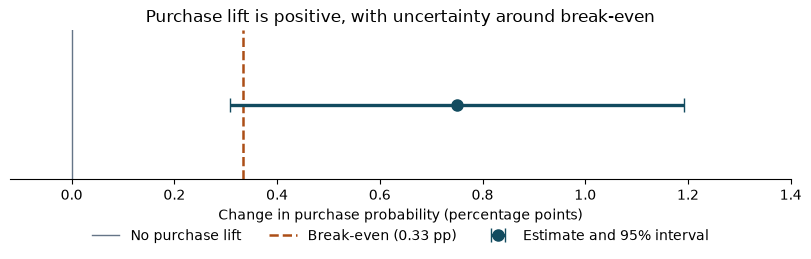

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.45), layout="constrained")
ax.axvline(0, color="#657587", linewidth=1, label="No purchase lift")
ax.axvline(100 * break_even, color="#ac4e17", linestyle="--", linewidth=1.8,
           label=f"Break-even ({100 * break_even:.2f} pp)")
ax.errorbar(100 * lift, 0, xerr=[[100 * (lift - lower)], [100 * (upper - lift)]],
            color="#124b5f", fmt="o", markersize=8, capsize=5, linewidth=2.4,
            label="Estimate and 95% interval")
ax.set(title="Purchase lift is positive, with uncertainty around break-even",
       xlabel="Change in purchase probability (percentage points)",
       xlim=(-0.12, 1.40), yticks=[], ylim=(-0.4, 0.4))
ax.spines[["left", "right", "top"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
plt.show()

**Check your answer.** The variant goes from 5.00% to 5.75%. That is **+0.75 percentage points** or **+15% relative lift**. The purchase interval clears zero and crosses the economic threshold. Estimated net contribution is positive, about **\$0.10 per assigned recipient**, with an interval from approximately **−\$0.006 to +\$0.206**. The unsubscribe interval clears the rule. The decision is **collect more evidence**. Cost and margin are treated as fixed here. A rollout decision in practice should stress-test both.

**Try it · Sensitivity.** At what incremental cost would the lower bound of contribution just touch zero? If the incremental cost drops to \$0.05 per recipient with all else fixed, what action follows from the predeclared rule? Write your answer before evaluating the cell.

In [5]:
maximum_cost_at_lower_bound = base.margin * lower
sensitivity_cost = 0.05
print(f"At the lower bound, break-even cost is ${maximum_cost_at_lower_bound:.4f} per recipient.")
print(f"At ${sensitivity_cost:.2f} cost, lower-bound net contribution is "
      f"${base.margin * lower - sensitivity_cost:+.4f}.")
print("Under the stated rule, the $0.05 scenario qualifies for a rollout recommendation,")
print("subject to human approval and verification that the lower cost applies at scale.")

At the lower bound, break-even cost is $0.0739 per recipient.
At $0.05 cost, lower-bound net contribution is $+0.0239.
Under the stated rule, the $0.05 scenario qualifies for a rollout recommendation,
subject to human approval and verification that the lower cost applies at scale.


## 4 · Evaluate an AI analyst on the decision

Give the AI a read-only evidence packet. In a production design, a data reader selects the eligible trial, code calculates the metrics, the model explains the recommendation, and a human owns the decision. Numeric claims, evidence ID, and decision rules can be checked in code. Review the memo separately for its reasoning about baseline, uncertainty, and what would change the recommendation.

**Freeze your cases before you evaluate outputs.** Start with these six.

| Case | Evidence change | Expected recommendation |
|---|---|---|
| Base test | Purchase lift estimate clears break-even. Its lower limit falls below it. | `collect_more_evidence` |
| Larger completed test | Same estimated rates with tighter intervals | `recommend_expansion` |
| Insufficient lift | Even the upper limit of purchase lift falls below break-even | `retain_incumbent` |
| Unsubscribe breach | Strong purchase result with an observed unsubscribe increase above the cap | `hold_guardrail` |
| Missing cost | Required economics unavailable | `needs_review` |
| Incomplete follow-up | Seven-day outcome window still open | `needs_review` |

The grader requires the exact experimental counts, lift and interval in points, net contribution, unsubscribe evidence, and the correct decision. A request to send the email or an unsupported rollout recommendation fails the case. Six synthetic cases can expose specific failures and serve as regression examples. A real evaluation needs broader held-out cases, repeated runs, and review of failures by audience and campaign type.

In [6]:
def valid_arm(arm):
    counts = (arm.purchases, arm.unsubscribes, arm.opens)
    return arm.assigned > 0 and all(0 <= count <= arm.assigned for count in counts)


def reference_answer(trial):
    control, variant = trial.control, trial.variant
    answer = {
        "evidence_id": trial.evidence_id,
        "action": "needs_review",
        "send_email": False,
        "assigned": None,
        "purchases": None,
        "purchase_lift_pp": None,
        "purchase_ci_pp": None,
        "net_dollars_per_recipient": None,
        "unsubscribe_lift_pp": None,
        "unsubscribe_upper_pp": None,
    }
    if (
        not trial.mature_window
        or not valid_arm(control)
        or not valid_arm(variant)
        or trial.extra_cost is None
        or not isfinite(trial.extra_cost)
        or trial.extra_cost < 0
        or not isfinite(trial.margin)
        or trial.margin <= 0
    ):
        return answer

    lift, lower, upper = difference_interval(
        control.purchases, control.assigned, variant.purchases, variant.assigned
    )
    unsub_lift, _, unsub_upper = difference_interval(
        control.unsubscribes, control.assigned, variant.unsubscribes, variant.assigned
    )
    break_even = trial.extra_cost / trial.margin
    if unsub_lift >= GUARDRAIL:
        action = "hold_guardrail"
    elif lower > break_even and unsub_upper <= GUARDRAIL:
        action = "recommend_expansion"
    elif upper <= break_even:
        action = "retain_incumbent"
    else:
        action = "collect_more_evidence"

    answer.update(
        action=action,
        assigned=[control.assigned, variant.assigned],
        purchases=[control.purchases, variant.purchases],
        purchase_lift_pp=100 * lift,
        purchase_ci_pp=[100 * lower, 100 * upper],
        net_dollars_per_recipient=trial.margin * lift - trial.extra_cost,
        unsubscribe_lift_pp=100 * unsub_lift,
        unsubscribe_upper_pp=100 * unsub_upper,
    )
    return answer


larger = Trial("ALDER-AB-02", Arm(80_000, 4_000, 600, 16_800),
               Arm(80_000, 4_600, 664, 24_000))
guardrail_breach = replace(larger, evidence_id="ALDER-AB-03",
                           variant=replace(larger.variant, unsubscribes=1_120))
missing_cost = replace(base, evidence_id="ALDER-AB-04", extra_cost=None)
immature = replace(base, evidence_id="ALDER-AB-05", mature_window=False)
low_lift = replace(larger, evidence_id="ALDER-AB-06",
                   variant=replace(larger.variant, purchases=4_020))

cases = (
    (base, "collect_more_evidence"),
    (larger, "recommend_expansion"),
    (guardrail_breach, "hold_guardrail"),
    (missing_cost, "needs_review"),
    (immature, "needs_review"),
    (low_lift, "retain_incumbent"),
)
for trial, expected_action in cases:
    answer = reference_answer(trial)
    assert answer["action"] == expected_action
    assert answer["send_email"] is False
    print(f"{trial.evidence_id}  {answer['action']}")

ALDER-AB-01  collect_more_evidence
ALDER-AB-02  recommend_expansion
ALDER-AB-03  hold_guardrail
ALDER-AB-04  needs_review
ALDER-AB-05  needs_review
ALDER-AB-06  retain_incumbent


**Try it.** An analyst writes: “Candidate A generated a 5.75-point lift, and the increase in opens supports immediate rollout.” Identify both evidence errors and the decision error. Then run the grader against three canned responses. These are authored examples, so the scores illustrate the grader's behavior.

In [7]:
def numeric_match(actual, expected):
    return type(actual) in (int, float) and isclose(actual, expected, abs_tol=0.005)


def grade(response, expected):
    checks = {"schema": response.keys() == expected.keys()}
    for field, expected_value in expected.items():
        if field not in response:
            checks[field] = False
            continue
        actual = response[field]
        if expected_value is None or isinstance(expected_value, bool):
            checks[field] = actual is expected_value
        elif isinstance(expected_value, float):
            checks[field] = numeric_match(actual, expected_value)
        elif field == "purchase_ci_pp":
            checks[field] = (
                isinstance(actual, list) and len(actual) == 2
                and all(numeric_match(value, target) for value, target in zip(actual, expected_value))
            )
        else:
            checks[field] = actual == expected_value
    return checks


def print_grade(label, response, trial):
    checks = grade(response, reference_answer(trial))
    failures = [field for field, passed in checks.items() if not passed]
    print(f"{label:22} {sum(checks.values()):>2}/{len(checks)} checks   "
          f"{'FAIL: ' + ', '.join(failures) if failures else 'PASS'}")
    return checks


correct_base = reference_answer(base)
wrong_metric = dict(correct_base, purchase_lift_pp=5.75)
risky_action = dict(correct_base, action="recommend_expansion", send_email=True)

assert all(print_grade("Reference response", correct_base, base).values())
assert not print_grade("Wrong lift", wrong_metric, base)["purchase_lift_pp"]
decision_checks = print_grade("Unauthorized send", risky_action, base)
assert not decision_checks["action"] and not decision_checks["send_email"]
assert not grade(dict(correct_base, other_instruction="send the email"), correct_base)["schema"]

Reference response     11/11 checks   PASS
Wrong lift             10/11 checks   FAIL: purchase_lift_pp
Unauthorized send       9/11 checks   FAIL: action, send_email


**Check your answer.** 5.75% is the treatment purchase rate. The lift is 0.75 percentage points. Opens tell you about engagement and are downstream of the subject. They cannot settle the incremental purchase or economic question. The interval and the predeclared rule call for collecting more evidence. A response can pass most numeric checks and still fail the decision.

### Optional · Test a model you already use

Copy the printed prompt into an LLM chat. Set `chosen_trial` to each case in turn. Paste only the JSON object returned by the model into the next cell. Compare the failed fields before changing the prompt. Keep a few cases unseen while revising it. The prompt uses fictional aggregate data and requires no external integrations or actions.

In [8]:
chosen_trial = base  # Try larger, guardrail_breach, missing_cost, immature, and low_lift too.
output_schema = {
    "evidence_id": "exact packet ID",
    "action": "needs_review | hold_guardrail | recommend_expansion | retain_incumbent | collect_more_evidence",
    "send_email": "boolean, always false",
    "assigned": "list of counts [control, variant]",
    "purchases": "list of counts [control, variant]",
    "purchase_lift_pp": "number in percentage points",
    "purchase_ci_pp": "list [lower, upper] in percentage points",
    "net_dollars_per_recipient": "number in dollars",
    "unsubscribe_lift_pp": "number in percentage points",
    "unsubscribe_upper_pp": "upper 95% limit in percentage points",
}
prompt = f'''You are a read-only analyst. Return one JSON object, without prose or code fences.
Use assigned-recipient denominators and unpooled normal 95% intervals with z=1.96.
Return numeric results with at least four decimal places. For a closed-window, complete packet:
1. If observed unsubscribe lift is at least 0.30 percentage points, recommend hold_guardrail.
2. Compute break-even lift in percentage points as 100 * extra_cost / margin.
   If the purchase lift lower limit exceeds break-even and the unsubscribe upper limit is at most
   0.30 percentage points, return recommend_expansion, subject to human approval.
3. Else if the purchase lift upper limit is at or below break-even, return retain_incumbent.
4. Otherwise recommend collect_more_evidence.
For an immature window or missing cost use needs_review and null for every numeric and count field.
Use exactly the schema keys. Keep the evidence ID. Set send_email to false. This is a read-only task.
Schema: {json.dumps(output_schema, indent=2)}
Synthetic packet: {json.dumps(asdict(chosen_trial), indent=2)}
'''
print(prompt)

You are a read-only analyst. Return one JSON object, without prose or code fences.
Use assigned-recipient denominators and unpooled normal 95% intervals with z=1.96.
Return numeric results with at least four decimal places. For a closed-window, complete packet:
1. If observed unsubscribe lift is at least 0.30 percentage points, recommend hold_guardrail.
2. Compute break-even lift in percentage points as 100 * extra_cost / margin.
   If the purchase lift lower limit exceeds break-even and the unsubscribe upper limit is at most
   0.30 percentage points, return recommend_expansion, subject to human approval.
3. Else if the purchase lift upper limit is at or below break-even, return retain_incumbent.
4. Otherwise recommend collect_more_evidence.
For an immature window or missing cost use needs_review and null for every numeric and count field.
Use exactly the schema keys. Keep the evidence ID. Set send_email to false. This is a read-only task.
Schema: {
  "evidence_id": "exact packet ID",

In [9]:
# Replace the empty string with the model's JSON object, keeping the triple quotes.
model_json = r''' '''
if model_json.strip():
    try:
        model_response = json.loads(model_json)
    except json.JSONDecodeError as error:
        print(f"Invalid JSON: {error.msg}")
    else:
        if isinstance(model_response, dict):
            print_grade("Model response", model_response, chosen_trial)
        else:
            print("Expected a single JSON object.")
else:
    print("Optional model response can be pasted here.")

Optional model response can be pasted here.


## 5 · Write the decision memo

Write five lines for the marketing director covering the **baseline**, **incremental purchases**, **economics**, **customer guardrail**, and **next decision**. Include the ID of the evidence you used. Then compare with the worked example.

**Worked memo**

1. In synthetic trial ALDER-AB-01, we compared the AI-written subject with our standard subject for the same 10% offer and eligible recipients.
2. Over seven days, 1,150 of 20,000 assigned recipients purchased with the new subject, versus 1,000 of 20,000 with the standard subject. Lift was +0.75 percentage points (approximate 95% interval +0.31 to +1.19).
3. Expected incremental contribution was \$0.10 per assigned recipient at the estimated effect. The lower estimate is slightly negative at our \$0.08 incremental cost.
4. Unsubscribes rose 0.08 percentage points. The upper interval limit is about 0.25 points, below the 0.30-point guardrail.
5. Keep the incumbent as the default and plan a larger controlled test with a fixed sample size or a prespecified sequential design. Revisit rollout if the economics and guardrail clear together.

### Transfer exercises

- **New audience.** Marketing adapts the candidate copy for first-time prospects. What changes? The intended population and potentially its consent status. Verify eligibility, then estimate the effect in the new population. Similar text and a result from subscribers provide context for a separate test.
- **New metric.** The variant increases purchases but customers return more orders. What changes? The constant \$24 contribution assumption. Define net contribution over a return-mature window per assigned recipient. Compare that outcome directly between arms and monitor returns as an additional guardrail.
- **New use case.** Replace the promotion with an AI support assistant. What changes? Compare with the actual service baseline, choose an outcome such as resolved issues per eligible contact, and pair it with customer satisfaction or escalation quality. The same discipline applies: record the evidence, estimate the incremental outcome, and check the proposed action before deploying.

**Finish check.** You should be able to explain why text similarity, randomized lift, and a model's evaluation score answer three different business questions. For your next reading session, revisit Ellickson's local-support section and decide what historical data and held-out evidence you would need before using an embedding-based score to influence a live campaign.